In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
%pip install -q ultralytics --no-deps
%pip install -q ultralytics-thop --no-deps

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 20.0 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import gc
import shutil
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from PIL import Image
from tqdm import tqdm

from ultralytics import YOLO

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
import joblib

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

WORK_DIR = Path("/kaggle/working")
OUTPUT_DIR = WORK_DIR / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def get_images(folder):
    folder = Path(folder)
    if not folder.exists():
        return []
    return [p for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXTS]


# Auto-find Prepared_Data folder
possible_dirs = []

for p in Path("/kaggle/input").rglob("Prepared_Data"):
    if (p / "train").exists() and (p / "val").exists() and (p / "test").exists():
        possible_dirs.append(p)

print("Possible dataset folders:")
for i, p in enumerate(possible_dirs):
    print(i, p)

DATASET_DIR = possible_dirs[0]

print("\nUsing dataset:", DATASET_DIR)

Possible dataset folders:
0 /kaggle/input/datasets/ruhul28amin/dumpalert-data-v2/Prepared_Data_Merged/Prepared_Data

Using dataset: /kaggle/input/datasets/ruhul28amin/dumpalert-data-v2/Prepared_Data_Merged/Prepared_Data


In [4]:
print("\n=== Dataset Count ===")

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")
    
    for cls in ["Positive", "Negative"]:
        folder = DATASET_DIR / split / cls
        imgs = get_images(folder)
        size_gb = sum(p.stat().st_size for p in imgs) / (1024 ** 3)
        print(f"{cls:<10} images: {len(imgs):<6} size: {size_gb:.2f} GB")


=== Dataset Count ===

TRAIN
Positive   images: 1368   size: 3.22 GB
Negative   images: 1957   size: 5.40 GB

VAL
Positive   images: 65     size: 0.20 GB
Negative   images: 57     size: 0.22 GB

TEST
Positive   images: 33     size: 0.12 GB
Negative   images: 30     size: 0.12 GB


In [ ]:
print("CUDA Available:", torch.cuda.is_available())
print("GPU Count:", torch.cuda.device_count())

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(i, torch.cuda.get_device_name(i))

In [ ]:
MODEL_SIZE = "yolov8x-cls.pt"

EPOCHS = 30
IMG_SIZE = 224
PATIENCE = 0

if torch.cuda.device_count() >= 2:
    DEVICE = "0,1"
    BATCH_SIZE = 64
else:
    DEVICE = 0
    BATCH_SIZE = 32

RUN_NAME = "yolov8x_cls_dumpalert"

model = YOLO(MODEL_SIZE)

results = model.train(
    data=str(DATASET_DIR),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=4,

    project=str(OUTPUT_DIR),
    name=RUN_NAME,
    exist_ok=True,

    patience=PATIENCE,
    lr0=1e-3,
    lrf=0.01,

    augment=False,
    flipud=0.1,
    fliplr=0.5,
    degrees=10,
    translate=0.1,
    scale=0.2,
    hsv_h=0.015,
    hsv_s=0.4,
    hsv_v=0.4,
    mixup=0.1,
    plots=True
)

YOLO_RUN_DIR = OUTPUT_DIR / RUN_NAME
YOLO_BEST_MODEL = YOLO_RUN_DIR / "weights" / "best.pt"
YOLO_FINAL_MODEL = OUTPUT_DIR / "yolov8x_cls_best.pt"

shutil.copy2(YOLO_BEST_MODEL, YOLO_FINAL_MODEL)

print("YOLO training complete.")
print("YOLO run dir:", YOLO_RUN_DIR)
print("Best model:", YOLO_BEST_MODEL)
print("Copied final model:", YOLO_FINAL_MODEL)
print("Best model exists:", YOLO_BEST_MODEL.exists())

In [ ]:
CLASS_NAMES_YOLO = ["Negative", "Positive"]  # YOLO usually sorts alphabetically
DISPLAY_NAMES = ["Clean", "Dump"]

def plot_confusion_matrix(cm, class_names, title, save_path):
    plt.figure(figsize=(6, 5))
    plt.imshow(cm)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.xticks(range(len(class_names)), class_names)
    plt.yticks(range(len(class_names)), class_names)

    for i in range(len(class_names)):
        for j in range(len(class_names)):
            plt.text(j, i, str(cm[i, j]), ha="center", va="center")

    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()


def evaluate_yolo_split(model_path, split_name):
    model_eval = YOLO(str(model_path))

    print("YOLO model names:", model_eval.names)

    y_true = []
    y_pred = []

    # Use model class order
    model_class_names = [model_eval.names[i] for i in sorted(model_eval.names.keys())]
    print("Class order:", model_class_names)

    for true_idx, cls_name in enumerate(model_class_names):
        cls_dir = DATASET_DIR / split_name / cls_name
        image_paths = get_images(cls_dir)

        for img_path in tqdm(image_paths, desc=f"YOLO {split_name} {cls_name}"):
            res = model_eval.predict(
                str(img_path),
                imgsz=IMG_SIZE,
                device=0,
                verbose=False
            )[0]

            pred_idx = int(res.probs.top1)

            y_true.append(true_idx)
            y_pred.append(pred_idx)

    acc = accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)

    print(f"\nYOLO {split_name.upper()} Accuracy:", acc)
    print(classification_report(y_true, y_pred, target_names=model_class_names))

    plot_confusion_matrix(
        cm,
        model_class_names,
        f"YOLOv8 Confusion Matrix - {split_name}",
        OUTPUT_DIR / f"yolov8_confusion_matrix_{split_name}.png"
    )

    report = classification_report(
        y_true,
        y_pred,
        target_names=model_class_names,
        output_dict=True
    )

    pd.DataFrame(report).transpose().to_csv(
        OUTPUT_DIR / f"yolov8_report_{split_name}.csv"
    )

    return acc


yolo_val_acc = evaluate_yolo_split(YOLO_BEST_MODEL, "val")
yolo_test_acc = evaluate_yolo_split(YOLO_BEST_MODEL, "test")

print("YOLO Validation Accuracy:", yolo_val_acc)
print("YOLO Test Accuracy:", yolo_test_acc)

In [ ]:
ML_OUTPUT_DIR = OUTPUT_DIR / "rf_svm_ann_models"
ML_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ML_IMG_SIZE = 64

# For sklearn models
# Label 0 = Clean/Negative
# Label 1 = Dump/Positive
CLASSES = ["Negative", "Positive"]
CLASS_DISPLAY = ["Clean", "Dump"]

def load_features(split):
    X = []
    y = []

    split_dir = DATASET_DIR / split

    for label, cls_name in enumerate(CLASSES):
        cls_dir = split_dir / cls_name
        image_paths = get_images(cls_dir)

        print(f"{split} - {cls_name}: {len(image_paths)} images")

        for img_path in tqdm(image_paths, desc=f"Loading {split} {cls_name}"):
            try:
                img = Image.open(img_path).convert("RGB")
                img = img.resize((ML_IMG_SIZE, ML_IMG_SIZE))

                arr = np.asarray(img, dtype=np.float32) / 255.0
                feature = arr.flatten()

                X.append(feature)
                y.append(label)

            except Exception as e:
                print("Skipped:", img_path, e)

    return np.array(X), np.array(y)


X_train, y_train = load_features("train")
X_val, y_val = load_features("val")
X_test, y_test = load_features("test")

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

joblib.dump(scaler, ML_OUTPUT_DIR / "scaler.joblib")

print("Scaler saved:", ML_OUTPUT_DIR / "scaler.joblib")

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

rf_train_acc = accuracy_score(y_train, rf_model.predict(X_train))
rf_val_acc = accuracy_score(y_val, rf_model.predict(X_val))

print(f"RF Train Accuracy: {rf_train_acc:.4f}")
print(f"RF Val Accuracy:   {rf_val_acc:.4f}")
print(classification_report(y_val, rf_model.predict(X_val), target_names=CLASS_DISPLAY))

joblib.dump(rf_model, ML_OUTPUT_DIR / "random_forest_model.joblib")
print("Random Forest saved:", ML_OUTPUT_DIR / "random_forest_model.joblib")

In [ ]:
svm_model = SVC(
    kernel="rbf",
    C=10,
    gamma="scale",
    probability=True,
    class_weight="balanced",
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

svm_train_acc = accuracy_score(y_train, svm_model.predict(X_train_scaled))
svm_val_acc = accuracy_score(y_val, svm_model.predict(X_val_scaled))

print(f"SVM Train Accuracy: {svm_train_acc:.4f}")
print(f"SVM Val Accuracy:   {svm_val_acc:.4f}")
print(classification_report(y_val, svm_model.predict(X_val_scaled), target_names=CLASS_DISPLAY))

joblib.dump(svm_model, ML_OUTPUT_DIR / "svm_model.joblib")
print("SVM saved:", ML_OUTPUT_DIR / "svm_model.joblib")

In [ ]:
ann_model = MLPClassifier(
    hidden_layer_sizes=(512, 256, 128),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    batch_size=64,
    learning_rate_init=0.001,
    max_iter=1,
    warm_start=True,
    early_stopping=False,
    random_state=42,
    verbose=False
)

best_val_acc = 0
patience = 20
no_improve = 0
best_weights = None

ann_history = []

for epoch in range(100):
    ann_model.fit(X_train_scaled, y_train)

    train_acc = accuracy_score(y_train, ann_model.predict(X_train_scaled))
    val_acc = accuracy_score(y_val, ann_model.predict(X_val_scaled))

    ann_history.append({
        "Epoch": epoch + 1,
        "Train Accuracy": train_acc,
        "Validation Accuracy": val_acc
    })

    print(f"Epoch {epoch+1:3d}: train={train_acc:.4f}  val={val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        no_improve = 0
        best_weights = (
            [l.copy() for l in ann_model.coefs_],
            [l.copy() for l in ann_model.intercepts_]
        )
    else:
        no_improve += 1
        if no_improve >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

# Restore best weights
ann_model.coefs_ = best_weights[0]
ann_model.intercepts_ = best_weights[1]

ann_train_acc = accuracy_score(y_train, ann_model.predict(X_train_scaled))
ann_val_acc = accuracy_score(y_val, ann_model.predict(X_val_scaled))

print(f"Best ANN val accuracy: {best_val_acc:.4f}")
print(f"ANN Train Accuracy after restore: {ann_train_acc:.4f}")
print(f"ANN Val Accuracy after restore:   {ann_val_acc:.4f}")

ann_history_df = pd.DataFrame(ann_history)
ann_history_df.to_csv(ML_OUTPUT_DIR / "ann_training_history.csv", index=False)

plt.figure(figsize=(10, 5))
plt.plot(ann_history_df["Epoch"], ann_history_df["Train Accuracy"], marker="o", label="Train Accuracy")
plt.plot(ann_history_df["Epoch"], ann_history_df["Validation Accuracy"], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN Training vs Validation Accuracy")
plt.grid(True)
plt.legend()
plt.savefig(ML_OUTPUT_DIR / "ann_train_val_accuracy_curve.png", dpi=150)
plt.show()

joblib.dump(ann_model, ML_OUTPUT_DIR / "ann_mlp_model.joblib")
print("ANN saved:", ML_OUTPUT_DIR / "ann_mlp_model.joblib")

In [ ]:
def evaluate_ml_model(model, X_data, y_data, model_name, split_name):
    preds = model.predict(X_data)
    acc = accuracy_score(y_data, preds)
    cm = confusion_matrix(y_data, preds)

    print(f"\n{model_name} {split_name.upper()} Accuracy:", acc)
    print(classification_report(y_data, preds, target_names=CLASS_DISPLAY))

    plot_confusion_matrix(
        cm,
        CLASS_DISPLAY,
        f"{model_name} Confusion Matrix - {split_name}",
        ML_OUTPUT_DIR / f"{model_name.lower().replace(' ', '_')}_confusion_matrix_{split_name}.png"
    )

    report = classification_report(
        y_data,
        preds,
        target_names=CLASS_DISPLAY,
        output_dict=True
    )

    pd.DataFrame(report).transpose().to_csv(
        ML_OUTPUT_DIR / f"{model_name.lower().replace(' ', '_')}_report_{split_name}.csv"
    )

    return acc


# Validation
rf_val_acc = evaluate_ml_model(rf_model, X_val, y_val, "Random Forest", "val")
svm_val_acc = evaluate_ml_model(svm_model, X_val_scaled, y_val, "SVM", "val")
ann_val_acc = evaluate_ml_model(ann_model, X_val_scaled, y_val, "ANN", "val")

# Test
rf_test_acc = evaluate_ml_model(rf_model, X_test, y_test, "Random Forest", "test")
svm_test_acc = evaluate_ml_model(svm_model, X_test_scaled, y_test, "SVM", "test")
ann_test_acc = evaluate_ml_model(ann_model, X_test_scaled, y_test, "ANN", "test")

In [ ]:
# ============================================================
# Training vs Validation vs Test Accuracy Comparison
# ============================================================

from ultralytics import YOLO
from sklearn.metrics import accuracy_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------------- YOLO Train + Val + Test Accuracy ----------------
yolo_eval = YOLO(str(YOLO_BEST_MODEL))

yolo_train_metrics = yolo_eval.val(
    data=str(DATASET_DIR),
    split="train",
    imgsz=224,
    batch=32,
    device=0,
    verbose=False
)

yolo_val_metrics = yolo_eval.val(
    data=str(DATASET_DIR),
    split="val",
    imgsz=224,
    batch=32,
    device=0,
    verbose=False
)

yolo_test_metrics = yolo_eval.val(
    data=str(DATASET_DIR),
    split="test",
    imgsz=224,
    batch=32,
    device=0,
    verbose=False
)

try:
    yolo_train_acc = float(yolo_train_metrics.top1)
except:
    yolo_train_acc = float(yolo_train_metrics.results_dict.get("metrics/accuracy_top1", 0))

try:
    yolo_val_acc = float(yolo_val_metrics.top1)
except:
    yolo_val_acc = float(yolo_val_metrics.results_dict.get("metrics/accuracy_top1", 0))

try:
    yolo_test_acc = float(yolo_test_metrics.top1)
except:
    yolo_test_acc = float(yolo_test_metrics.results_dict.get("metrics/accuracy_top1", 0))


# ---------------- RF Train + Val + Test Accuracy ----------------
rf_train_acc = accuracy_score(y_train, rf_model.predict(X_train))
rf_val_acc   = accuracy_score(y_val, rf_model.predict(X_val))
rf_test_acc  = accuracy_score(y_test, rf_model.predict(X_test))


# ---------------- SVM Train + Val + Test Accuracy ----------------
svm_train_acc = accuracy_score(y_train, svm_model.predict(X_train_scaled))
svm_val_acc   = accuracy_score(y_val, svm_model.predict(X_val_scaled))
svm_test_acc  = accuracy_score(y_test, svm_model.predict(X_test_scaled))


# ---------------- ANN Train + Val + Test Accuracy ----------------
ann_train_acc = accuracy_score(y_train, ann_model.predict(X_train_scaled))
ann_val_acc   = accuracy_score(y_val, ann_model.predict(X_val_scaled))
ann_test_acc  = accuracy_score(y_test, ann_model.predict(X_test_scaled))


# ---------------- Comparison Table ----------------
train_val_test_df = pd.DataFrame({
    "Model": ["YOLOv8x-cls", "Random Forest", "SVM", "ANN"],
    "Training Accuracy": [yolo_train_acc, rf_train_acc, svm_train_acc, ann_train_acc],
    "Validation Accuracy": [yolo_val_acc, rf_val_acc, svm_val_acc, ann_val_acc],
    "Test Accuracy": [yolo_test_acc, rf_test_acc, svm_test_acc, ann_test_acc]
})

print(train_val_test_df)

train_val_test_df.to_csv(
    OUTPUT_DIR / "training_validation_test_accuracy.csv",
    index=False
)


# ---------------- Bar Plot ----------------
x = np.arange(len(train_val_test_df["Model"]))
width = 0.25

plt.figure(figsize=(12, 6))

plt.bar(
    x - width,
    train_val_test_df["Training Accuracy"],
    width,
    label="Training Accuracy"
)

plt.bar(
    x,
    train_val_test_df["Validation Accuracy"],
    width,
    label="Validation Accuracy"
)

plt.bar(
    x + width,
    train_val_test_df["Test Accuracy"],
    width,
    label="Test Accuracy"
)

plt.xticks(x, train_val_test_df["Model"])
plt.ylabel("Accuracy")
plt.title("Training vs Validation vs Test Accuracy")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y")

for i, v in enumerate(train_val_test_df["Training Accuracy"]):
    plt.text(i - width, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)

for i, v in enumerate(train_val_test_df["Validation Accuracy"]):
    plt.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)

for i, v in enumerate(train_val_test_df["Test Accuracy"]):
    plt.text(i + width, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_validation_test_accuracy.png", dpi=150)
plt.show()

print("Saved CSV:", OUTPUT_DIR / "training_validation_test_accuracy.csv")
print("Saved Plot:", OUTPUT_DIR / "training_validation_test_accuracy.png")

In [1]:
%pip install -q ultralytics gdown

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 20.4 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 86.0 MB/s eta 0:00:00:00:010:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires nu

In [2]:
import os
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm import tqdm

import joblib
from ultralytics import YOLO

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [4]:
from pathlib import Path

INPUT_ROOT = Path("/kaggle/input")

print("Searching all best.pt files...\n")

best_models = list(INPUT_ROOT.rglob("best.pt"))

for i, p in enumerate(best_models):
    print(i, p)

print("\nTotal best.pt found:", len(best_models))

Searching all best.pt files...

0 /kaggle/input/models/ruhulamiinn/dump/other/default/1/output/yolov8x_cls_dumpalert/weights/best.pt

Total best.pt found: 1


In [5]:
from pathlib import Path
from ultralytics import YOLO

# Auto find YOLO best.pt
best_models = list(Path("/kaggle/input").rglob("best.pt"))

if len(best_models) == 0:
    raise FileNotFoundError("No best.pt found inside /kaggle/input")

# Prefer the best.pt inside yolov8x_cls_dumpalert/weights
YOLO_MODEL_PATH = None

for p in best_models:
    if "yolov8x_cls_dumpalert" in str(p) and "weights" in str(p):
        YOLO_MODEL_PATH = p
        break

# fallback: first best.pt
if YOLO_MODEL_PATH is None:
    YOLO_MODEL_PATH = best_models[0]

print("Using YOLO model:", YOLO_MODEL_PATH)
print("Exists:", YOLO_MODEL_PATH.exists())

model = YOLO(str(YOLO_MODEL_PATH))
print("Model loaded successfully.")
print("Model class names:", model.names)

Using YOLO model: /kaggle/input/models/ruhulamiinn/dump/other/default/1/output/yolov8x_cls_dumpalert/weights/best.pt
Exists: True
Model loaded successfully.
Model class names: {0: 'Negative', 1: 'Positive'}


In [6]:
from pathlib import Path
import numpy as np

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def get_images(folder):
    folder = Path(folder)
    return [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMG_EXTS
    ]

# Auto-find Test_critical dataset folder
print("Kaggle input folders:")
for p in Path("/kaggle/input").iterdir():
    print(p)

possible_test_dirs = []

for p in Path("/kaggle/input").rglob("*"):
    if p.is_dir() and "test" in p.name.lower() and "critical" in p.name.lower():
        possible_test_dirs.append(p)

print("\nPossible critical test folders:")
for i, p in enumerate(possible_test_dirs):
    print(i, p)

# Usually this will be the correct folder
TEST_DOWNLOAD_DIR = possible_test_dirs[0]

test_images = get_images(TEST_DOWNLOAD_DIR)

print("\nUsing test folder:", TEST_DOWNLOAD_DIR)
print("Total critical negative test images found:", len(test_images))

for p in test_images[:10]:
    print(p)

# Since all test images are Negative/Clean
TRUE_LABEL = 0
CLASS_NAMES = ["Negative", "Positive"]   # 0 = Clean/Negative, 1 = Dump/Positive
DISPLAY_NAMES = ["Clean/Negative", "Dump/Positive"]

y_true = np.zeros(len(test_images), dtype=int)

Kaggle input folders:
/kaggle/input/models
/kaggle/input/datasets

Possible critical test folders:
0 /kaggle/input/datasets/ruhulamiinn/test-critical

Using test folder: /kaggle/input/datasets/ruhulamiinn/test-critical
Total critical negative test images found: 61
/kaggle/input/datasets/ruhulamiinn/test-critical/IMG20260628155451.jpg
/kaggle/input/datasets/ruhulamiinn/test-critical/IMG20260628152823_01.jpg.jpeg
/kaggle/input/datasets/ruhulamiinn/test-critical/IMG20260628153235.jpg.jpeg
/kaggle/input/datasets/ruhulamiinn/test-critical/IMG20260628152802.jpg
/kaggle/input/datasets/ruhulamiinn/test-critical/IMG20260628155526_01.jpg.jpeg
/kaggle/input/datasets/ruhulamiinn/test-critical/IMG20260628155558_01.jpg.jpeg
/kaggle/input/datasets/ruhulamiinn/test-critical/IMG20260628155033_01.jpg.jpeg
/kaggle/input/datasets/ruhulamiinn/test-critical/IMG20260628155437_01.jpg.jpeg
/kaggle/input/datasets/ruhulamiinn/test-critical/IMG20260628160317.jpg
/kaggle/input/datasets/ruhulamiinn/test-critical/IM

In [7]:
INPUT_ROOT = Path("/kaggle/input")

print("Searching models inside:", INPUT_ROOT)

yolo_models = list(INPUT_ROOT.rglob("best.pt"))
rf_models = list(INPUT_ROOT.rglob("random_forest_model.joblib"))
svm_models = list(INPUT_ROOT.rglob("svm_model.joblib"))
ann_models = list(INPUT_ROOT.rglob("ann_mlp_model.joblib"))
scalers = list(INPUT_ROOT.rglob("scaler.joblib"))

print("YOLO models:", yolo_models)
print("RF models:", rf_models)
print("SVM models:", svm_models)
print("ANN models:", ann_models)
print("Scalers:", scalers)

YOLO_MODEL_PATH = yolo_models[0]
RF_MODEL_PATH = rf_models[0]
SVM_MODEL_PATH = svm_models[0]
ANN_MODEL_PATH = ann_models[0]
SCALER_PATH = scalers[0]

print("\nUsing:")
print("YOLO:", YOLO_MODEL_PATH)
print("RF:", RF_MODEL_PATH)
print("SVM:", SVM_MODEL_PATH)
print("ANN:", ANN_MODEL_PATH)
print("Scaler:", SCALER_PATH)

Searching models inside: /kaggle/input
YOLO models: [PosixPath('/kaggle/input/models/ruhulamiinn/dump/other/default/1/output/yolov8x_cls_dumpalert/weights/best.pt')]
RF models: [PosixPath('/kaggle/input/models/ruhulamiinn/dump/other/default/1/output/rf_svm_ann_models/random_forest_model.joblib')]
SVM models: [PosixPath('/kaggle/input/models/ruhulamiinn/dump/other/default/1/output/rf_svm_ann_models/svm_model.joblib')]
ANN models: [PosixPath('/kaggle/input/models/ruhulamiinn/dump/other/default/1/output/rf_svm_ann_models/ann_mlp_model.joblib')]
Scalers: [PosixPath('/kaggle/input/models/ruhulamiinn/dump/other/default/1/output/rf_svm_ann_models/scaler.joblib')]

Using:
YOLO: /kaggle/input/models/ruhulamiinn/dump/other/default/1/output/yolov8x_cls_dumpalert/weights/best.pt
RF: /kaggle/input/models/ruhulamiinn/dump/other/default/1/output/rf_svm_ann_models/random_forest_model.joblib
SVM: /kaggle/input/models/ruhulamiinn/dump/other/default/1/output/rf_svm_ann_models/svm_model.joblib
ANN: /kaggl

In [8]:
OUTPUT_DIR = Path("/kaggle/working/negative_test_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Results will be saved at:", OUTPUT_DIR)

Results will be saved at: /kaggle/working/negative_test_results


In [9]:
def plot_confusion_matrix(cm, class_names, title, save_path):
    plt.figure(figsize=(6, 5))
    plt.imshow(cm)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.xticks(range(len(class_names)), class_names, rotation=20)
    plt.yticks(range(len(class_names)), class_names)

    for i in range(len(class_names)):
        for j in range(len(class_names)):
            plt.text(j, i, str(cm[i, j]), ha="center", va="center")

    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()


def save_report(model_name, y_true, y_pred, save_prefix):
    acc = accuracy_score(y_true, y_pred)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    report_text = classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=DISPLAY_NAMES,
        zero_division=0
    )

    report_dict = classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=DISPLAY_NAMES,
        output_dict=True,
        zero_division=0
    )

    print("\n==============================")
    print(model_name)
    print("==============================")
    print("Accuracy:", acc)
    print(report_text)

    pd.DataFrame(report_dict).transpose().to_csv(
        OUTPUT_DIR / f"{save_prefix}_classification_report.csv"
    )

    plot_confusion_matrix(
        cm,
        DISPLAY_NAMES,
        f"{model_name} Confusion Matrix on Negative Test Data",
        OUTPUT_DIR / f"{save_prefix}_confusion_matrix.png"
    )

    return acc, cm

YOLO class names: {0: 'Negative', 1: 'Positive'}


YOLO predicting: 100%|██████████| 61/61 [00:19<00:00,  3.17it/s]



YOLOv8x-cls
Accuracy: 0.8688524590163934
                precision    recall  f1-score   support

Clean/Negative       1.00      0.87      0.93        61
 Dump/Positive       0.00      0.00      0.00         0

      accuracy                           0.87        61
     macro avg       0.50      0.43      0.46        61
  weighted avg       1.00      0.87      0.93        61



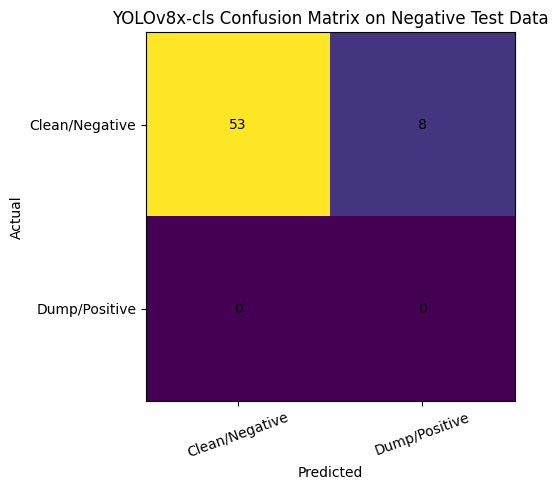

In [10]:
yolo_model = YOLO(str(YOLO_MODEL_PATH))

print("YOLO class names:", yolo_model.names)

yolo_preds = []
yolo_conf = []

for img_path in tqdm(test_images, desc="YOLO predicting"):
    result = yolo_model.predict(
        str(img_path),
        imgsz=224,
        device=0,
        verbose=False
    )[0]

    pred_idx = int(result.probs.top1)
    conf = float(result.probs.top1conf)

    yolo_preds.append(pred_idx)
    yolo_conf.append(conf)

yolo_preds = np.array(yolo_preds)

yolo_acc, yolo_cm = save_report(
    "YOLOv8x-cls",
    y_true,
    yolo_preds,
    "yolov8"
)

yolo_df = pd.DataFrame({
    "image_path": [str(p) for p in test_images],
    "true_label": "Negative",
    "predicted_index": yolo_preds,
    "predicted_label": [CLASS_NAMES[i] for i in yolo_preds],
    "confidence": yolo_conf
})

yolo_df.to_csv(OUTPUT_DIR / "yolov8_predictions.csv", index=False)

In [11]:
ML_IMG_SIZE = 64

def extract_features(image_paths):
    X = []
    valid_paths = []

    for img_path in tqdm(image_paths, desc="Extracting features"):
        try:
            img = Image.open(img_path).convert("RGB")
            img = img.resize((ML_IMG_SIZE, ML_IMG_SIZE))

            arr = np.asarray(img, dtype=np.float32) / 255.0
            feature = arr.flatten()

            X.append(feature)
            valid_paths.append(img_path)

        except Exception as e:
            print("Skipped:", img_path, e)

    return np.array(X), valid_paths

X_test_new, valid_test_paths = extract_features(test_images)

y_true_ml = np.zeros(len(valid_test_paths), dtype=int)

print("Feature shape:", X_test_new.shape)
print("Valid test images:", len(valid_test_paths))

Extracting features: 100%|██████████| 61/61 [00:13<00:00,  4.46it/s]

Feature shape: (61, 12288)
Valid test images: 61


In [12]:
rf_model = joblib.load(RF_MODEL_PATH)
svm_model = joblib.load(SVM_MODEL_PATH)
ann_model = joblib.load(ANN_MODEL_PATH)
scaler = joblib.load(SCALER_PATH)

X_test_new_scaled = scaler.transform(X_test_new)

print("Models loaded successfully.")

Models loaded successfully.



Random Forest
Accuracy: 1.0
                precision    recall  f1-score   support

Clean/Negative       1.00      1.00      1.00        61
 Dump/Positive       0.00      0.00      0.00         0

      accuracy                           1.00        61
     macro avg       0.50      0.50      0.50        61
  weighted avg       1.00      1.00      1.00        61



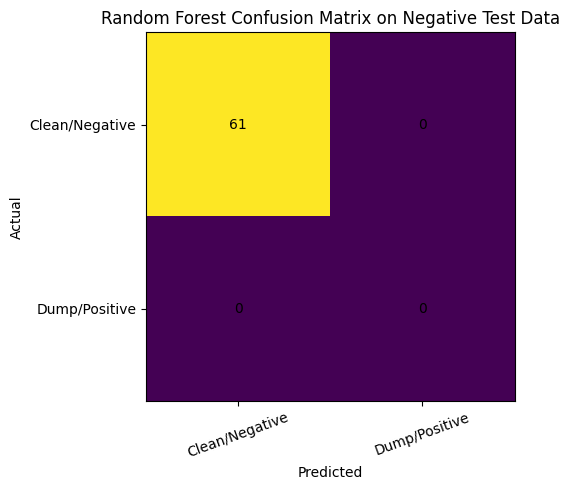

In [13]:
rf_preds = rf_model.predict(X_test_new)

if hasattr(rf_model, "predict_proba"):
    rf_probs = rf_model.predict_proba(X_test_new)
    rf_conf = rf_probs.max(axis=1)
else:
    rf_conf = [None] * len(rf_preds)

rf_acc, rf_cm = save_report(
    "Random Forest",
    y_true_ml,
    rf_preds,
    "random_forest"
)

rf_df = pd.DataFrame({
    "image_path": [str(p) for p in valid_test_paths],
    "true_label": "Negative",
    "predicted_index": rf_preds,
    "predicted_label": [CLASS_NAMES[i] for i in rf_preds],
    "confidence": rf_conf
})

rf_df.to_csv(OUTPUT_DIR / "random_forest_predictions.csv", index=False)


SVM
Accuracy: 0.8524590163934426
                precision    recall  f1-score   support

Clean/Negative       1.00      0.85      0.92        61
 Dump/Positive       0.00      0.00      0.00         0

      accuracy                           0.85        61
     macro avg       0.50      0.43      0.46        61
  weighted avg       1.00      0.85      0.92        61



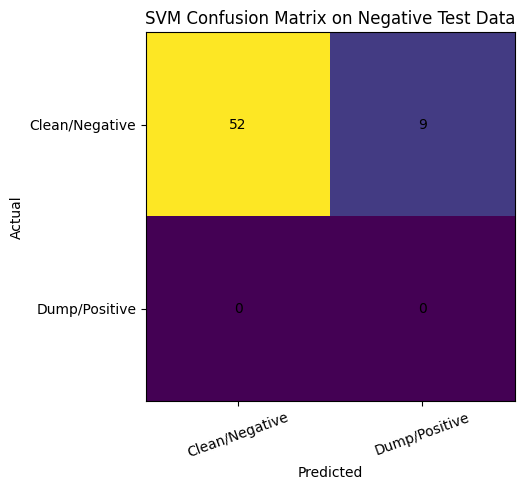

In [14]:
svm_preds = svm_model.predict(X_test_new_scaled)

if hasattr(svm_model, "predict_proba"):
    svm_probs = svm_model.predict_proba(X_test_new_scaled)
    svm_conf = svm_probs.max(axis=1)
else:
    svm_conf = [None] * len(svm_preds)

svm_acc, svm_cm = save_report(
    "SVM",
    y_true_ml,
    svm_preds,
    "svm"
)

svm_df = pd.DataFrame({
    "image_path": [str(p) for p in valid_test_paths],
    "true_label": "Negative",
    "predicted_index": svm_preds,
    "predicted_label": [CLASS_NAMES[i] for i in svm_preds],
    "confidence": svm_conf
})

svm_df.to_csv(OUTPUT_DIR / "svm_predictions.csv", index=False)


ANN / MLP
Accuracy: 0.7049180327868853
                precision    recall  f1-score   support

Clean/Negative       1.00      0.70      0.83        61
 Dump/Positive       0.00      0.00      0.00         0

      accuracy                           0.70        61
     macro avg       0.50      0.35      0.41        61
  weighted avg       1.00      0.70      0.83        61



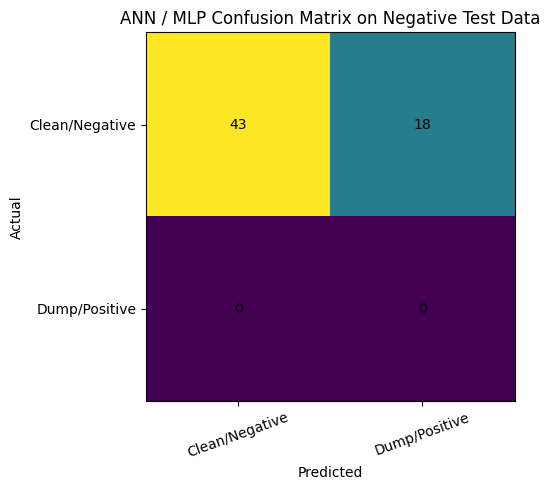

In [15]:
ann_preds = ann_model.predict(X_test_new_scaled)

if hasattr(ann_model, "predict_proba"):
    ann_probs = ann_model.predict_proba(X_test_new_scaled)
    ann_conf = ann_probs.max(axis=1)
else:
    ann_conf = [None] * len(ann_preds)

ann_acc, ann_cm = save_report(
    "ANN / MLP",
    y_true_ml,
    ann_preds,
    "ann"
)

ann_df = pd.DataFrame({
    "image_path": [str(p) for p in valid_test_paths],
    "true_label": "Negative",
    "predicted_index": ann_preds,
    "predicted_label": [CLASS_NAMES[i] for i in ann_preds],
    "confidence": ann_conf
})

ann_df.to_csv(OUTPUT_DIR / "ann_predictions.csv", index=False)

           Model  Negative Test Accuracy  Total Test Images  \
0    YOLOv8x-cls                0.868852                 61   
1  Random Forest                1.000000                 61   
2            SVM                0.852459                 61   
3            ANN                0.704918                 61   

   Wrongly Predicted as Dump  Correctly Predicted as Clean  
0                          8                            53  
1                          0                            61  
2                          9                            52  
3                         18                            43  


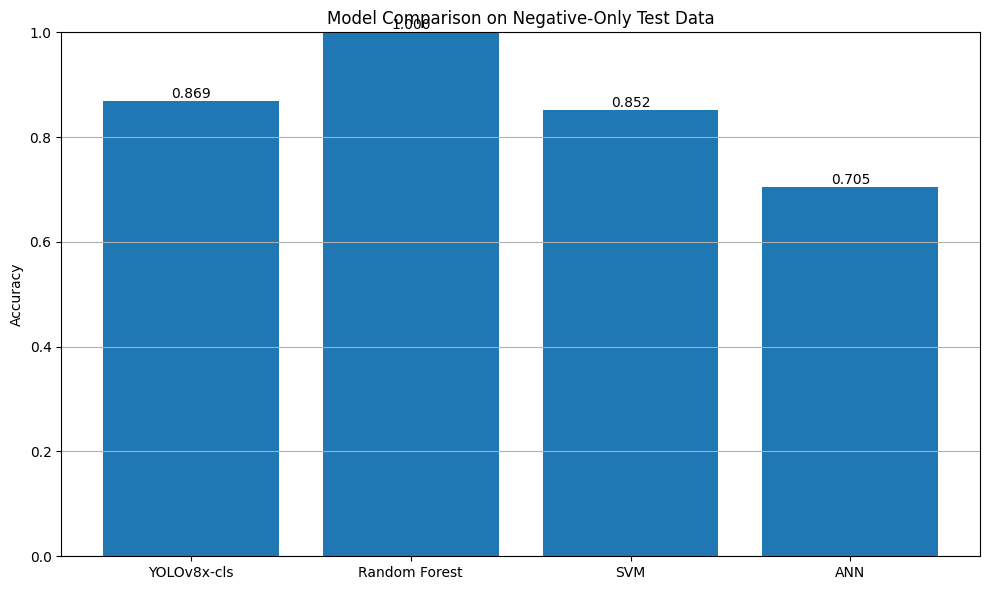

In [16]:
comparison_df = pd.DataFrame({
    "Model": ["YOLOv8x-cls", "Random Forest", "SVM", "ANN"],
    "Negative Test Accuracy": [yolo_acc, rf_acc, svm_acc, ann_acc],
    "Total Test Images": [len(y_true), len(y_true_ml), len(y_true_ml), len(y_true_ml)],
    "Wrongly Predicted as Dump": [
        int((yolo_preds == 1).sum()),
        int((rf_preds == 1).sum()),
        int((svm_preds == 1).sum()),
        int((ann_preds == 1).sum())
    ],
    "Correctly Predicted as Clean": [
        int((yolo_preds == 0).sum()),
        int((rf_preds == 0).sum()),
        int((svm_preds == 0).sum()),
        int((ann_preds == 0).sum())
    ]
})

print(comparison_df)

comparison_df.to_csv(OUTPUT_DIR / "negative_test_model_comparison.csv", index=False)

plt.figure(figsize=(10, 6))
plt.bar(comparison_df["Model"], comparison_df["Negative Test Accuracy"])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Model Comparison on Negative-Only Test Data")
plt.grid(axis="y")

for i, v in enumerate(comparison_df["Negative Test Accuracy"]):
    plt.text(i, v, f"{v:.3f}", ha="center", va="bottom")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "negative_test_model_comparison.png", dpi=150)
plt.show()

In [17]:
combined_df = pd.DataFrame({
    "image_path": [str(p) for p in valid_test_paths],
    "true_label": "Negative",

    "YOLO_prediction": yolo_df["predicted_label"].values[:len(valid_test_paths)],
    "YOLO_confidence": yolo_df["confidence"].values[:len(valid_test_paths)],

    "RF_prediction": rf_df["predicted_label"].values,
    "RF_confidence": rf_df["confidence"].values,

    "SVM_prediction": svm_df["predicted_label"].values,
    "SVM_confidence": svm_df["confidence"].values,

    "ANN_prediction": ann_df["predicted_label"].values,
    "ANN_confidence": ann_df["confidence"].values,
})

combined_df.to_csv(OUTPUT_DIR / "all_model_predictions_on_negative_test.csv", index=False)

print(combined_df.head())

                                          image_path true_label  \
0  /kaggle/input/datasets/ruhulamiinn/test-critic...   Negative   
1  /kaggle/input/datasets/ruhulamiinn/test-critic...   Negative   
2  /kaggle/input/datasets/ruhulamiinn/test-critic...   Negative   
3  /kaggle/input/datasets/ruhulamiinn/test-critic...   Negative   
4  /kaggle/input/datasets/ruhulamiinn/test-critic...   Negative   

  YOLO_prediction  YOLO_confidence RF_prediction  RF_confidence  \
0        Negative         0.681834      Negative       0.850000   
1        Negative         0.993278      Negative       0.823333   
2        Negative         0.708368      Negative       0.616667   
3        Negative         0.850363      Negative       0.670000   
4        Negative         0.977572      Negative       0.726667   

  SVM_prediction  SVM_confidence ANN_prediction  ANN_confidence  
0       Negative        0.500000       Positive        0.895455  
1       Negative        0.690611       Positive        0.73808

In [18]:
zip_file = shutil.make_archive(
    base_name="/kaggle/working/negative_test_results",
    format="zip",
    root_dir=str(OUTPUT_DIR)
)

print("ZIP created:", zip_file)

ZIP created: /kaggle/working/negative_test_results.zip


In [6]:
from pathlib import Path

INPUT_ROOT = Path("/kaggle/input")

print("Searching all best.pt files...\n")

best_models = list(INPUT_ROOT.rglob("best.pt"))

for i, p in enumerate(best_models):
    print(i, p)

print("\nTotal best.pt found:", len(best_models))

Searching all best.pt files...

0 /kaggle/input/models/ruhulamiinn/dump/other/default/1/output/yolov8x_cls_dumpalert/weights/best.pt

Total best.pt found: 1


In [7]:
from pathlib import Path
from ultralytics import YOLO

# Auto find YOLO best.pt
best_models = list(Path("/kaggle/input").rglob("best.pt"))

if len(best_models) == 0:
    raise FileNotFoundError("No best.pt found inside /kaggle/input")

# Prefer the best.pt inside yolov8x_cls_dumpalert/weights
YOLO_MODEL_PATH = None

for p in best_models:
    if "yolov8x_cls_dumpalert" in str(p) and "weights" in str(p):
        YOLO_MODEL_PATH = p
        break

# fallback: first best.pt
if YOLO_MODEL_PATH is None:
    YOLO_MODEL_PATH = best_models[0]

print("Using YOLO model:", YOLO_MODEL_PATH)
print("Exists:", YOLO_MODEL_PATH.exists())

model = YOLO(str(YOLO_MODEL_PATH))
print("Model loaded successfully.")
print("Model class names:", model.names)

Using YOLO model: /kaggle/input/models/ruhulamiinn/dump/other/default/1/output/yolov8x_cls_dumpalert/weights/best.pt
Exists: True
Model loaded successfully.
Model class names: {0: 'Negative', 1: 'Positive'}


In [8]:
from pathlib import Path
import pandas as pd
import numpy as np
import shutil
from tqdm import tqdm

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def get_images(folder):
    folder = Path(folder)
    if not folder.exists():
        return []
    return [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMG_EXTS
    ]

# Auto find Prepared_Data folder
possible_dataset_dirs = []

for p in Path("/kaggle/input").rglob("Prepared_Data"):
    if (p / "val").exists() and (p / "train").exists():
        possible_dataset_dirs.append(p)

print("Possible dataset folders:")
for i, p in enumerate(possible_dataset_dirs):
    print(i, p)

DATASET_DIR = possible_dataset_dirs[0]
print("\nUsing DATASET_DIR:", DATASET_DIR)

print("\nValidation counts:")
for cls in ["Negative", "Positive"]:
    print(cls, len(get_images(DATASET_DIR / "val" / cls)))

Possible dataset folders:
0 /kaggle/input/datasets/ruhul28amin/dumpalert-data-v2/Prepared_Data_Merged/Prepared_Data

Using DATASET_DIR: /kaggle/input/datasets/ruhul28amin/dumpalert-data-v2/Prepared_Data_Merged/Prepared_Data

Validation counts:
Negative 57
Positive 65


In [9]:
OUTPUT_DIR = Path("/kaggle/working/manual_error_analysis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

rows = []

for actual_label in ["Negative", "Positive"]:
    image_paths = get_images(DATASET_DIR / "val" / actual_label)

    for img_path in tqdm(image_paths, desc=f"Checking val/{actual_label}"):

        result = model.predict(
            str(img_path),
            imgsz=224,
            device=0,
            verbose=False
        )[0]

        pred_idx = int(result.probs.top1)
        pred_label = model.names[pred_idx]
        confidence = float(result.probs.top1conf)

        correct = actual_label == pred_label

        rows.append({
            "image_path": str(img_path),
            "image_name": img_path.name,
            "actual_label": actual_label,
            "predicted_label": pred_label,
            "confidence": confidence,
            "correct": correct,

            # Fill these manually later
            "error_type": "",
            "possible_reason": "",
            "scene_description": "",
            "human_difficulty": "",
            "suggested_fix": "",
            "reviewer_name": ""
        })

val_df = pd.DataFrame(rows)

misclassified_df = val_df[val_df["correct"] == False].copy()
low_conf_df = val_df.sort_values("confidence").head(50).copy()

val_df.to_csv(OUTPUT_DIR / "all_validation_predictions.csv", index=False)
misclassified_df.to_csv(OUTPUT_DIR / "validation_misclassified_images.csv", index=False)
low_conf_df.to_csv(OUTPUT_DIR / "low_confidence_validation_images.csv", index=False)

print("Total validation images:", len(val_df))
print("Misclassified validation images:", len(misclassified_df))
print("Low confidence images saved:", len(low_conf_df))

display(misclassified_df.head())
display(low_conf_df.head())

Checking val/Positive: 100%|██████████| 65/65 [00:14<00:00,  4.37it/s]

Total validation images: 122
Misclassified validation images: 1
Low confidence images saved: 50


,image_path,image_name,actual_label,predicted_label,confidence,correct,error_type,possible_reason,scene_description,human_difficulty,suggested_fix,reviewer_name
60,/kaggle/input/datasets/ruhul28amin/dumpalert-d...,8_fecede40_18fe27011399.jpg,Positive,Negative,0.999611,False,,,,,,


,image_path,image_name,actual_label,predicted_label,confidence,correct,error_type,possible_reason,scene_description,human_difficulty,suggested_fix,reviewer_name
16,/kaggle/input/datasets/ruhul28amin/dumpalert-d...,IMG_20260418_065055_76d1f583_2e3a86b9d6dd.jpg,Negative,Negative,0.795261,True,,,,,,
82,/kaggle/input/datasets/ruhul28amin/dumpalert-d...,IMG_20260418_055820_af25efb0_180b0ba05e3b.jpg,Positive,Positive,0.849122,True,,,,,,
78,/kaggle/input/datasets/ruhul28amin/dumpalert-d...,IMG_20260420_150354_932_513cf896_b028fa2852b7.jpg,Positive,Positive,0.911876,True,,,,,,
35,/kaggle/input/datasets/ruhul28amin/dumpalert-d...,IMG_20260420_143358_303_932d5339_8f7bc7bc8d2c.jpg,Negative,Negative,0.930749,True,,,,,,
24,/kaggle/input/datasets/ruhul28amin/dumpalert-d...,IMG_0073_92fbaaba_f955a4048277.jpg,Negative,Negative,0.932602,True,,,,,,


In [10]:
MIS_IMG_DIR = OUTPUT_DIR / "misclassified_validation_images"
MIS_IMG_DIR.mkdir(parents=True, exist_ok=True)

for _, row in misclassified_df.iterrows():
    src = Path(row["image_path"])
    actual = row["actual_label"]
    pred = row["predicted_label"]

    dst_dir = MIS_IMG_DIR / f"actual_{actual}_pred_{pred}"
    dst_dir.mkdir(parents=True, exist_ok=True)

    shutil.copy2(src, dst_dir / src.name)

print("Misclassified images copied to:", MIS_IMG_DIR)

Misclassified images copied to: /kaggle/working/manual_error_analysis/misclassified_validation_images


In [11]:
zip_file = shutil.make_archive(
    base_name="/kaggle/working/manual_error_analysis_output",
    format="zip",
    root_dir=str(OUTPUT_DIR)
)

print("ZIP created:", zip_file)

ZIP created: /kaggle/working/manual_error_analysis_output.zip


In [12]:
import joblib
from pathlib import Path

INPUT_ROOT = Path("/kaggle/input")

rf_paths = list(INPUT_ROOT.rglob("random_forest_model.joblib"))
svm_paths = list(INPUT_ROOT.rglob("svm_model.joblib"))
ann_paths = list(INPUT_ROOT.rglob("ann_mlp_model.joblib"))
scaler_paths = list(INPUT_ROOT.rglob("scaler.joblib"))

print("RF found:", rf_paths)
print("SVM found:", svm_paths)
print("ANN found:", ann_paths)
print("Scaler found:", scaler_paths)

RF_MODEL_PATH = rf_paths[0]
SVM_MODEL_PATH = svm_paths[0]
ANN_MODEL_PATH = ann_paths[0]
SCALER_PATH = scaler_paths[0]

rf_model = joblib.load(RF_MODEL_PATH)
svm_model = joblib.load(SVM_MODEL_PATH)
ann_model = joblib.load(ANN_MODEL_PATH)
scaler = joblib.load(SCALER_PATH)

print("RF loaded:", RF_MODEL_PATH)
print("SVM loaded:", SVM_MODEL_PATH)
print("ANN loaded:", ANN_MODEL_PATH)
print("Scaler loaded:", SCALER_PATH)

RF found: [PosixPath('/kaggle/input/models/ruhulamiinn/dump/other/default/1/output/rf_svm_ann_models/random_forest_model.joblib')]
SVM found: [PosixPath('/kaggle/input/models/ruhulamiinn/dump/other/default/1/output/rf_svm_ann_models/svm_model.joblib')]
ANN found: [PosixPath('/kaggle/input/models/ruhulamiinn/dump/other/default/1/output/rf_svm_ann_models/ann_mlp_model.joblib')]
Scaler found: [PosixPath('/kaggle/input/models/ruhulamiinn/dump/other/default/1/output/rf_svm_ann_models/scaler.joblib')]
RF loaded: /kaggle/input/models/ruhulamiinn/dump/other/default/1/output/rf_svm_ann_models/random_forest_model.joblib
SVM loaded: /kaggle/input/models/ruhulamiinn/dump/other/default/1/output/rf_svm_ann_models/svm_model.joblib
ANN loaded: /kaggle/input/models/ruhulamiinn/dump/other/default/1/output/rf_svm_ann_models/ann_mlp_model.joblib
Scaler loaded: /kaggle/input/models/ruhulamiinn/dump/other/default/1/output/rf_svm_ann_models/scaler.joblib


In [13]:
from PIL import Image
from tqdm import tqdm
import numpy as np
import pandas as pd

ML_IMG_SIZE = 64

# Label mapping same as your training:
# 0 = Negative / Clean
# 1 = Positive / Dump
CLASS_NAMES = ["Negative", "Positive"]

def extract_ml_features_from_val():
    X = []
    y = []
    paths = []

    for label, cls_name in enumerate(CLASS_NAMES):
        img_paths = get_images(DATASET_DIR / "val" / cls_name)

        print(f"Validation {cls_name}: {len(img_paths)} images")

        for img_path in tqdm(img_paths, desc=f"Extracting {cls_name}"):
            try:
                img = Image.open(img_path).convert("RGB")
                img = img.resize((ML_IMG_SIZE, ML_IMG_SIZE))

                arr = np.asarray(img, dtype=np.float32) / 255.0
                feature = arr.flatten()

                X.append(feature)
                y.append(label)
                paths.append(img_path)

            except Exception as e:
                print("Skipped:", img_path, e)

    return np.array(X), np.array(y), paths


X_val_ml, y_val_ml, val_paths_ml = extract_ml_features_from_val()

X_val_ml_scaled = scaler.transform(X_val_ml)

print("X_val_ml shape:", X_val_ml.shape)
print("Total val images:", len(val_paths_ml))

Validation Negative: 57 images


Extracting Negative: 100%|██████████| 57/57 [00:15<00:00,  3.58it/s]


Validation Positive: 65 images


Extracting Positive: 100%|██████████| 65/65 [00:12<00:00,  5.36it/s]

X_val_ml shape: (122, 12288)
Total val images: 122


In [15]:
import shutil
from sklearn.metrics import accuracy_score, classification_report

ML_ERROR_DIR = Path("/kaggle/working/manual_error_analysis/ml_models")
ML_ERROR_DIR.mkdir(parents=True, exist_ok=True)

def make_ml_error_analysis(model, model_name, X_data, y_true, image_paths, use_proba=True):
    model_dir = ML_ERROR_DIR / model_name.lower().replace(" ", "_")
    model_dir.mkdir(parents=True, exist_ok=True)

    preds = model.predict(X_data)

    # Confidence
    if use_proba and hasattr(model, "predict_proba"):
        probs = model.predict_proba(X_data)
        confs = probs.max(axis=1)
    else:
        confs = np.ones(len(preds))

    rows = []

    for img_path, actual_idx, pred_idx, conf in zip(image_paths, y_true, preds, confs):
        actual_label = CLASS_NAMES[int(actual_idx)]
        pred_label = CLASS_NAMES[int(pred_idx)]
        correct = actual_label == pred_label

        rows.append({
            "image_path": str(img_path),
            "image_name": Path(img_path).name,
            "actual_label": actual_label,
            "predicted_label": pred_label,
            "confidence": float(conf),
            "correct": correct,

            # Fill these manually later
            "error_type": "",
            "possible_reason": "",
            "scene_description": "",
            "human_difficulty": "",
            "suggested_fix": "",
            "reviewer_name": ""
        })

    df = pd.DataFrame(rows)

    misclassified_df = df[df["correct"] == False].copy()
    low_conf_df = df.sort_values("confidence").head(50).copy()

    df.to_csv(model_dir / f"{model_name}_all_validation_predictions.csv", index=False)
    misclassified_df.to_csv(model_dir / f"{model_name}_validation_misclassified_images.csv", index=False)
    low_conf_df.to_csv(model_dir / f"{model_name}_low_confidence_validation_images.csv", index=False)

    # Copy misclassified images
    mis_img_dir = model_dir / "misclassified_validation_images"
    mis_img_dir.mkdir(parents=True, exist_ok=True)

    for _, row in misclassified_df.iterrows():
        src = Path(row["image_path"])
        actual = row["actual_label"]
        pred = row["predicted_label"]

        dst_dir = mis_img_dir / f"actual_{actual}_pred_{pred}"
        dst_dir.mkdir(parents=True, exist_ok=True)

        shutil.copy2(src, dst_dir / src.name)

    # Copy low confidence images
    low_conf_dir = model_dir / "low_confidence_validation_images"
    low_conf_dir.mkdir(parents=True, exist_ok=True)

    for _, row in low_conf_df.iterrows():
        src = Path(row["image_path"])
        actual = row["actual_label"]
        pred = row["predicted_label"]
        conf = row["confidence"]

        dst_name = f"conf_{conf:.3f}_actual_{actual}_pred_{pred}_{src.name}"
        shutil.copy2(src, low_conf_dir / dst_name)

    acc = accuracy_score(y_true, preds)

    print("\n==============================")
    print(model_name)
    print("==============================")
    print("Validation Accuracy:", acc)
    print("Misclassified images:", len(misclassified_df))
    print("Low-confidence images saved:", len(low_conf_df))
    print(classification_report(y_true, preds, target_names=CLASS_NAMES, zero_division=0))
    print("Saved at:", model_dir)

    return df, misclassified_df, low_conf_df

In [16]:
# Random Forest uses unscaled X
rf_all_df, rf_mis_df, rf_low_df = make_ml_error_analysis(
    model=rf_model,
    model_name="Random_Forest",
    X_data=X_val_ml,
    y_true=y_val_ml,
    image_paths=val_paths_ml
)

# SVM uses scaled X
svm_all_df, svm_mis_df, svm_low_df = make_ml_error_analysis(
    model=svm_model,
    model_name="SVM",
    X_data=X_val_ml_scaled,
    y_true=y_val_ml,
    image_paths=val_paths_ml
)

# ANN uses scaled X
ann_all_df, ann_mis_df, ann_low_df = make_ml_error_analysis(
    model=ann_model,
    model_name="ANN",
    X_data=X_val_ml_scaled,
    y_true=y_val_ml,
    image_paths=val_paths_ml
)


Random_Forest
Validation Accuracy: 0.8934426229508197
Misclassified images: 13
Low-confidence images saved: 50
              precision    recall  f1-score   support

    Negative       0.91      0.86      0.88        57
    Positive       0.88      0.92      0.90        65

    accuracy                           0.89       122
   macro avg       0.89      0.89      0.89       122
weighted avg       0.89      0.89      0.89       122

Saved at: /kaggle/working/manual_error_analysis/ml_models/random_forest

SVM
Validation Accuracy: 0.8688524590163934
Misclassified images: 16
Low-confidence images saved: 50
              precision    recall  f1-score   support

    Negative       0.82      0.93      0.87        57
    Positive       0.93      0.82      0.87        65

    accuracy                           0.87       122
   macro avg       0.87      0.87      0.87       122
weighted avg       0.88      0.87      0.87       122

Saved at: /kaggle/working/manual_error_analysis/ml_models/sv

In [17]:
summary_df = pd.DataFrame({
    "Model": ["Random Forest", "SVM", "ANN"],
    "Validation Images": [len(rf_all_df), len(svm_all_df), len(ann_all_df)],
    "Misclassified Images": [len(rf_mis_df), len(svm_mis_df), len(ann_mis_df)],
    "Low Confidence Images Saved": [len(rf_low_df), len(svm_low_df), len(ann_low_df)],
    "Validation Accuracy": [
        accuracy_score(y_val_ml, rf_model.predict(X_val_ml)),
        accuracy_score(y_val_ml, svm_model.predict(X_val_ml_scaled)),
        accuracy_score(y_val_ml, ann_model.predict(X_val_ml_scaled))
    ]
})

summary_df.to_csv(ML_ERROR_DIR / "ml_models_error_analysis_summary.csv", index=False)

print(summary_df)

           Model  Validation Images  Misclassified Images  \
0  Random Forest                122                    13   
1            SVM                122                    16   
2            ANN                122                    12   

   Low Confidence Images Saved  Validation Accuracy  
0                           50             0.893443  
1                           50             0.868852  
2                           50             0.901639  


In [18]:
zip_file = shutil.make_archive(
    base_name="/kaggle/working/ml_manual_error_analysis_output",
    format="zip",
    root_dir=str(ML_ERROR_DIR)
)

print("ZIP created:", zip_file)

ZIP created: /kaggle/working/ml_manual_error_analysis_output.zip


In [19]:
import shutil
from pathlib import Path

# Auto-find Prepared_Data folder
possible_dataset_dirs = []

for p in Path("/kaggle/input").rglob("Prepared_Data"):
    if (p / "val").exists():
        possible_dataset_dirs.append(p)

print("Possible Prepared_Data folders:")
for i, p in enumerate(possible_dataset_dirs):
    print(i, p)

DATASET_DIR = possible_dataset_dirs[0]
VAL_DIR = DATASET_DIR / "val"

print("Using VAL_DIR:", VAL_DIR)
print("Exists:", VAL_DIR.exists())

# Output folder
EXPORT_DIR = Path("/kaggle/working/validation_images_export")

if EXPORT_DIR.exists():
    shutil.rmtree(EXPORT_DIR)

EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# Copy val folder
shutil.copytree(VAL_DIR, EXPORT_DIR / "val")

print("Validation images copied to:", EXPORT_DIR / "val")

Possible Prepared_Data folders:
0 /kaggle/input/datasets/ruhul28amin/dumpalert-data-v2/Prepared_Data_Merged/Prepared_Data
Using VAL_DIR: /kaggle/input/datasets/ruhul28amin/dumpalert-data-v2/Prepared_Data_Merged/Prepared_Data/val
Exists: True
Validation images copied to: /kaggle/working/validation_images_export/val


In [20]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def get_images(folder):
    return [
        p for p in Path(folder).rglob("*")
        if p.is_file() and p.suffix.lower() in IMG_EXTS
    ]

for cls in ["Negative", "Positive"]:
    imgs = get_images(EXPORT_DIR / "val" / cls)
    print(cls, len(imgs))

print("Total validation images:", len(get_images(EXPORT_DIR / "val")))

Negative 57
Positive 65
Total validation images: 122


In [21]:
zip_file = shutil.make_archive(
    base_name="/kaggle/working/validation_images",
    format="zip",
    root_dir=str(EXPORT_DIR)
)

print("ZIP created:", zip_file)

ZIP created: /kaggle/working/validation_images.zip
